In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.api as sm
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

sns.set_theme(style='whitegrid')

#Load and explore

In [ ]:
df = pd.read_csv('regression_housing_dataset.csv')
print('Shape:', df.shape)

# Simple regression needs only one predictor (square_feet) and the target (price)
data = df[['square_feet', 'price_usd_k']]
print('Missing values:\n', data.isnull().sum())
data.describe()

Shape: (1000, 11)
Missing values:
 square_feet    0
price_usd_k    0
dtype: int64


,square_feet,price_usd_k
count,1000.000000,1000.00000
mean,1808.226000,228.02359
std,390.302792,62.49437
min,800.000000,30.68000
25%,1540.750000,185.43000
50%,1810.000000,229.22500
75%,2059.000000,269.43000
max,3341.000000,421.39000


#Scatter Plot

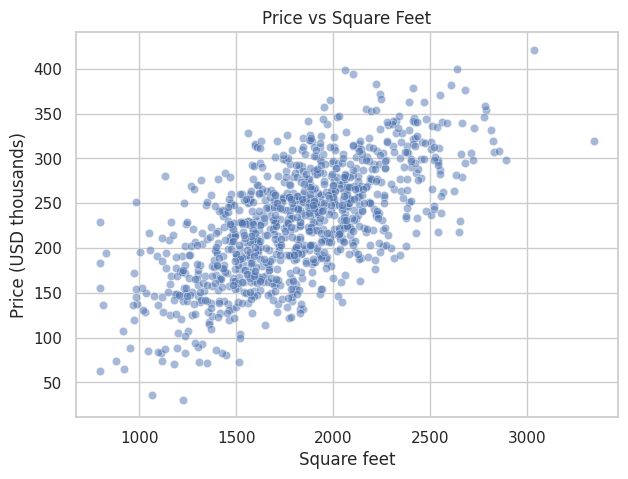

Correlation: 0.6618


In [ ]:
# Check that the relationship looks roughly linear before fitting a line
plt.figure(figsize=(7, 5))
sns.scatterplot(data=data, x='square_feet', y='price_usd_k', alpha=0.5)
plt.title('Price vs Square Feet')
plt.xlabel('Square feet')
plt.ylabel('Price (USD thousands)')
plt.show()

print('Correlation:', round(data['square_feet'].corr(data['price_usd_k']), 4))

#OLS with statsmodels (full data, for interpretation)

In [ ]:
# statsmodels does not add an intercept automatically, so add a constant column
X_simple = sm.add_constant(df[['square_feet']])
simple_model = sm.OLS(df['price_usd_k'], X_simple).fit()
print(simple_model.summary())

b0, b1 = simple_model.params['const'], simple_model.params['square_feet']
print(f'Intercept (b0): {b0:.4f}')
print(f'Slope (b1):     {b1:.4f}')   # price change (USD k) per extra square foot
print(f'R-squared:      {simple_model.rsquared:.4f}')

                            OLS Regression Results                            
Dep. Variable:            price_usd_k   R-squared:                       0.438
Model:                            OLS   Adj. R-squared:                  0.437
Method:                 Least Squares   F-statistic:                     777.5
Date:                Tue, 20 Oct 2026   Prob (F-statistic):          5.40e-127
Time:                        18:03:05   Log-Likelihood:                -5265.5
No. Observations:                1000   AIC:                         1.053e+04
Df Residuals:                     998   BIC:                         1.054e+04
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                  coef    std err          t      P>|t|      [0.025      0.975]
-------------------------------------------------------------------------------
const          36.4273      7.029      5.182      

## Hypothesis Test: Is Square Feet a Significant Predictor?

**Test used:** t-test on the slope coefficient (β1)

- **Null hypothesis (H0):** β1 = 0, square feet has no linear effect on price
- **Alternative hypothesis (H1):** β1 ≠ 0, square feet has a linear effect on price
- **Significance level:** α = 0.05

| Coefficient | Estimate | t-statistic | p-value | 95% CI |
|---|---|---|---|---|
| square_feet | 0.1060 | 27.884 | 5.40e-127 | [0.099, 0.113] |

**Decision:** p-value (≈ 0) < 0.05, so we **reject H0**.

**Conclusion:** there is strong statistical evidence that square feet has a significant linear relationship with price. Each extra square foot is associated with an increase of about 0.106 (USD thousands) in price. The confidence interval does not contain 0, which agrees with the test result.

#Train/test split with scikit-learn (no standardization)

In [ ]:
X = df[['square_feet']]   # double brackets keep X as a 2D DataFrame (sklearn needs this)
y = df['price_usd_k']

# 80% train / 20% test; random_state makes the split reproducible
x_train, x_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=20)

model = LinearRegression()
model.fit(x_train, y_train)
print(f'Intercept: {model.intercept_:.4f}')
print(f'Slope:     {model.coef_[0]:.4f}')

y_pred_train = model.predict(x_train)
y_pred_test = model.predict(x_test)

# Similar train and test scores mean the model is not overfitting
# RMSE = square root of MSE, so it is in the same units as price
results = pd.DataFrame({
    'Metric': ['R-squared', 'RMSE', 'MAE'],
    'Train': [r2_score(y_train, y_pred_train),
              np.sqrt(mean_squared_error(y_train, y_pred_train)),
              mean_absolute_error(y_train, y_pred_train)],
    'Test':  [r2_score(y_test, y_pred_test),
              np.sqrt(mean_squared_error(y_test, y_pred_test)),
              mean_absolute_error(y_test, y_pred_test)],
}).round(4)
results

Intercept: 38.3658
Slope:     0.1049


,Metric,Train,Test
0,R-squared,0.4380,0.4374
1,RMSE,46.5483,47.9491
2,MAE,37.7394,37.8456


# Fitted line

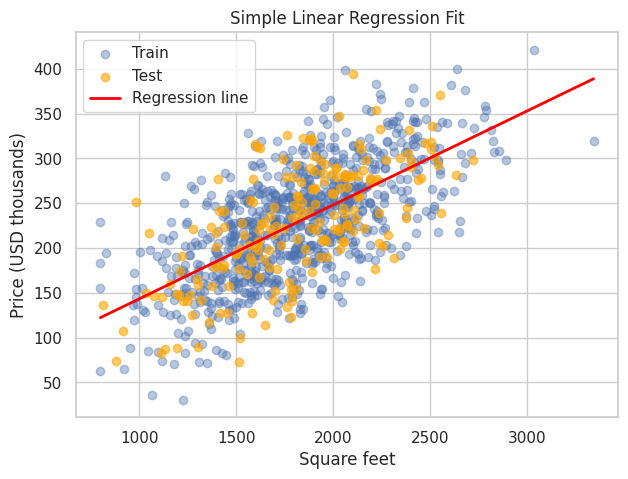

In [ ]:
plt.figure(figsize=(7, 5))
plt.scatter(x_train, y_train, alpha=0.4, label='Train')
plt.scatter(x_test, y_test, alpha=0.6, color='orange', label='Test')

# Evenly spaced x values across the data range to draw a smooth line
line_x = pd.DataFrame({'square_feet': np.linspace(X['square_feet'].min(), X['square_feet'].max(), 100)})
plt.plot(line_x, model.predict(line_x), color='red', linewidth=2, label='Regression line')

plt.title('Simple Linear Regression Fit')
plt.xlabel('Square feet')
plt.ylabel('Price (USD thousands)')
plt.legend()
plt.show()

**Predict for new houses**

In [ ]:
# Input must be a DataFrame with the same column name used in training
new_house = pd.DataFrame({'square_feet': [1800, 2500]})
preds = model.predict(new_house)
for sqft, p in zip(new_house['square_feet'], preds):
    print(f'{sqft} sq ft -> predicted price: {p:.1f}k USD')

1800 sq ft -> predicted price: 227.3k USD
2500 sq ft -> predicted price: 300.7k USD


#Residual analysis

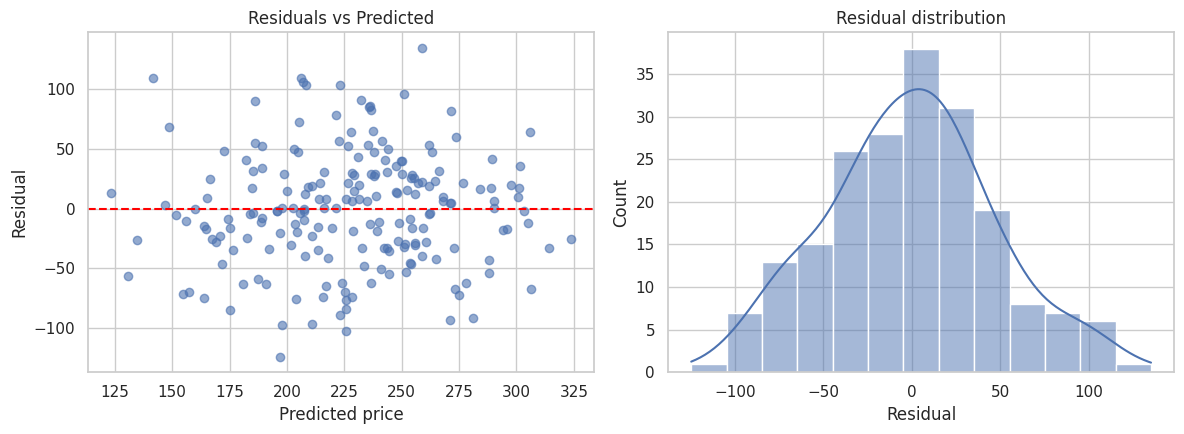

In [ ]:
# Residual = actual - predicted; it should scatter randomly around 0 with no pattern
residuals = y_test - y_pred_test

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

axes[0].scatter(y_pred_test, residuals, alpha=0.6)
axes[0].axhline(0, color='red', linestyle='--')
axes[0].set_title('Residuals vs Predicted')
axes[0].set_xlabel('Predicted price')
axes[0].set_ylabel('Residual')

# A roughly bell-shaped histogram centred at 0 means residuals are close to normal
sns.histplot(residuals, kde=True, ax=axes[1])
axes[1].set_title('Residual distribution')
axes[1].set_xlabel('Residual')

plt.tight_layout()
plt.show()